In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# import dataset

In [13]:
from sklearn.datasets import fetch_openml

data=fetch_openml(data_id=43463)
df=pd.DataFrame(data=data['data'])
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [14]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

# Spliting dataset

In [15]:
X, y = df[df.columns[:-1]], df[df.columns[-1]]

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

# Preprocessing

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

categorical_cols = ['sex', 'children', 'smoker', 'region']
numerical_cols = ['age', 'bmi']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

In [18]:
X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)
y_train =  y_train.to_numpy().reshape(-1,1)
y_val = y_val.to_numpy().reshape(-1,1)
y_test = y_test.to_numpy().reshape(-1,1)

In [19]:
target_scaler = StandardScaler()
y_train = target_scaler.fit_transform(y_train)
y_val = target_scaler.fit_transform(y_val)
y_test = target_scaler.fit_transform(y_test)

# Feed Forward Neural Network

In [ ]:
class FeedForwardNN:
    def __init__(self,
                n_layers:int,
                n_neurons:int,
                learning_rate=0.001,
                n_epochs=10000,
                batch_size=1024,
                patience=10,
                random_state=42
            ) -> None:
        self._n_layers = n_layers
        self._n_neurons = n_neurons
        self._learning_rate = learning_rate
        self._batch_size = batch_size
        self._n_epochs = n_epochs
        self._patience = patience
        self._rng = np.random.default_rng(random_state)
        self._weights = []
        self._biases = []
        self.history = {"train_loss": [], "val_loss": []}

    def _init_params(self, n_inputs:int, n_outputs:int):
        layer_sizes = [n_inputs] + [self._n_neurons]*(self._n_layers-1) + [n_outputs]
        
        self._weights = [self._rng.normal(0, np.sqrt(2/layer_sizes[i]),
                                          (layer_sizes[i], layer_sizes[i+1]))
                         for i in range(len(layer_sizes)-1)]
        self._biases = [np.zeros((1, layer_sizes[i+1])) for i in range(len(layer_sizes)-1)]

    def _activation(self, x):
        return np.maximum(0, x)

    def _activation_deriv(self, x):
        return (x > 0).astype(float)

    def _forward(self, X):
        activations = [X]
        pre_activations = []
        for W, b in zip(self._weights[:-1], self._biases[:-1]):
            Z = activations[-1] @ W + b
            pre_activations.append(Z)
            A = self._activation(Z)
            activations.append(A)
        
        Z = activations[-1] @ self._weights[-1] + self._biases[-1]
        pre_activations.append(Z)
        activations.append(Z)
        return activations, pre_activations

    def _backward(self, activations, pre_activations, y_true):
        grads_W, grads_b = [], []
        dA = 2 * (activations[-1] - y_true) / y_true.shape[0]

        for i in reversed(range(len(self._weights))):
            dZ = dA
            if i < len(self._weights)-1:
                dZ = dA * self._activation_deriv(pre_activations[i])

            dW = activations[i].T @ dZ
            db = np.sum(dZ, axis=0, keepdims=True)
            dA = dZ @ self._weights[i].T

            grads_W.insert(0, dW)
            grads_b.insert(0, db)

        return grads_W, grads_b

    def fit(self, X_train:np.ndarray, y_train:np.ndarray,
            X_val:np.ndarray, y_val:np.ndarray, logging:bool=False):
        n_samples, n_features = X_train.shape
        n_outputs = y_train.shape[1] if y_train.ndim > 1 else 1
        if y_train.ndim == 1:
            y_train = y_train.reshape(-1, 1)
            y_val = y_val.reshape(-1, 1)

        self._init_params(n_features, n_outputs)

        best_val_loss = np.inf
        best_weights, best_biases = None, None
        patience_counter = 0

        for epoch in range(self._n_epochs):
            indices = self._rng.permutation(n_samples)
            for start in range(0, n_samples, self._batch_size):
                end = start + self._batch_size
                batch_idx = indices[start:end]
                X_batch, y_batch = X_train[batch_idx], y_train[batch_idx]

                activations, pre_activations = self._forward(X_batch)
                grads_W, grads_b = self._backward(activations, pre_activations, y_batch)

                for i in range(len(self._weights)):
                    self._weights[i] -= self._learning_rate * grads_W[i]
                    self._biases[i] -= self._learning_rate * grads_b[i]

            train_preds = self.predict(X_train)
            train_loss = np.mean((train_preds - y_train)**2)

            val_preds = self.predict(X_val)
            val_loss = np.mean((val_preds - y_val)**2)

            self.history["train_loss"].append(train_loss)
            self.history["val_loss"].append(val_loss)

            if logging and epoch % 10 == 0:
                print(f"Epoch {epoch}: Train MSE={train_loss:.4f}, Val MSE={val_loss:.4f}")

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_weights = [w.copy() for w in self._weights]
                best_biases = [b.copy() for b in self._biases]
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= self._patience:
                    if logging:
                        print(f"Early stopping at epoch {epoch}, best val MSE={best_val_loss:.4f}")
                    break

        self._weights = best_weights
        self._biases = best_biases

    def predict(self, X:np.ndarray) -> np.ndarray:
        activations, _ = self._forward(X)
        return activations[-1]


In [21]:
from itertools import product
from concurrent.futures import ProcessPoolExecutor
from sklearn.metrics import r2_score

def train_and_score(params, X_train, y_train, X_val, y_val):
    n_neurons, n_layers = params
    model = FeedForwardNN(
        n_neurons=n_neurons,
        n_layers=n_layers
    )

    model.fit(X_train, y_train, X_val, y_val)
    preds = model.predict(X_val)
    preds = preds.reshape(-1)
    r2 = r2_score(y_val, preds)
    return (params, r2)

def grid_search(X_train, y_train, X_val, y_val):
    n_neurons = [32, 64, 128]
    n_layers = [2, 3]

    param_grid = list(product(n_neurons, n_layers))

    results = []
    with ProcessPoolExecutor() as executor:
        futures = [
            executor.submit(train_and_score, params, X_train, y_train, X_val, y_val)
            for params in param_grid
        ]
        for f in futures:
            results.append(f.result())
    
    best_params, best_r2 = max(results, key=lambda x: x[1])
    return best_params, best_r2, results

In [22]:
best_params, best_r2, results = grid_search(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val)

In [37]:
print(f'best r2 score {best_r2}')
print(f'best neurones per layer: {best_params[0]}')
print(f'best number of layer: {best_params[1]}')

best r2 score 0.8288146542520083
best neurones per layer: 128
best number of layer: 3


# Model Evaluation

In [28]:
best_model = FeedForwardNN(n_neurons=best_params[0] ,n_layers=best_params[1])

best_model.fit(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val)

best_y_pred = best_model.predict(X_test)

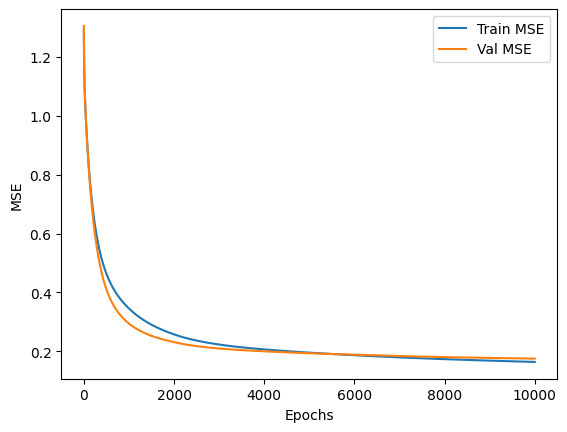

In [30]:
plt.plot(best_model.history["train_loss"], label="Train MSE")
plt.plot(best_model.history["val_loss"], label="Val MSE")
plt.xlabel("Epochs")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [32]:
from sklearn.metrics import mean_squared_error

best_mse=mean_squared_error(y_true=y_test, y_pred=best_y_pred)
best_r2=r2_score(y_true=y_test, y_pred=best_y_pred)

print(f'mse: {best_mse}')
print(f'r2 score: {best_r2}')


mse: 0.1711853457479918
r2 score: 0.8288146542520083


# prediction vs truth

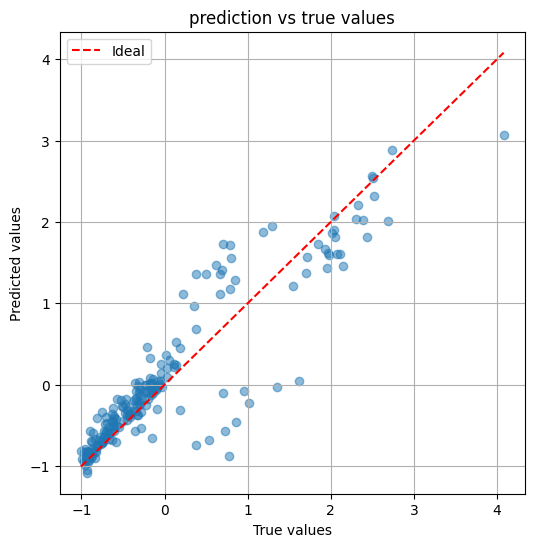

In [35]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, best_y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Ideal")
plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.title("prediction vs true values")
plt.legend()
plt.grid(True)
plt.show()

# Sklearn comparision

In [39]:
from sklearn.neural_network import MLPRegressor

sk_model = MLPRegressor(hidden_layer_sizes=[best_params[0] for _ in range(best_params[1])], activation='relu')
sk_model.fit(X=X_train, y=y_train)
sk_pred = sk_model.predict(X_test)
sk_r2 = r2_score(y_test, sk_pred)
sk_mse = mean_squared_error(y_test, sk_pred)
print(f'sklearn r2 score {sk_r2}')
print(f'sklearn mse {sk_mse}')
print(f'custom NN r2 score: {best_r2}')
print(f'custom NN mse {best_mse}')

/home/kingshuk/codespace/pyprojs/ML_Labs/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:1771: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


sklearn r2 score 0.7936164064217334
sklearn mse 0.20638359357826666
custom NN r2 score: 0.8288146542520083
custom NN mse 0.1711853457479918


/home/kingshuk/codespace/pyprojs/ML_Labs/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


# sklearn prediction vs truth

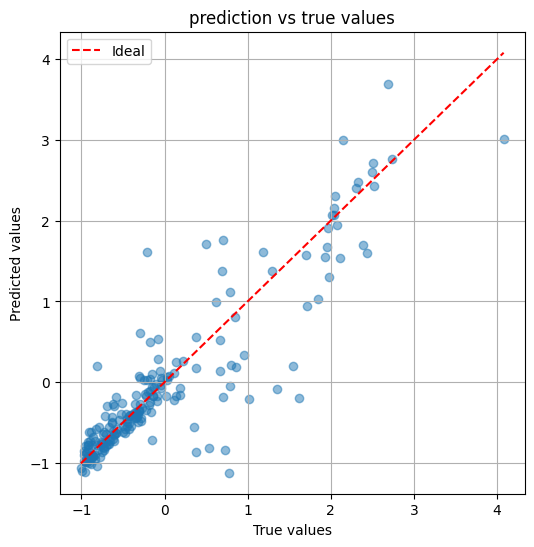

In [41]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, sk_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Ideal")
plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.title("prediction vs true values")
plt.legend()
plt.grid(True)
plt.show()